# 03 — Model Evaluation and Final Demo

**Purpose:** compare train / CV / validation / test scores for all models, inspect confusion matrices, per-class and per-blood-type performance, High-risk recall, regression errors, before-vs-after optimization, and print next-week forecasts for the final observed week. This notebook only **reads** saved results and models; it does not retrain.

In [1]:
# CMD: Run this cell first. Makes imports work whether Jupyter starts from the project root or notebooks/.
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Open Jupyter from the Blood-Type-ML project directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
print('Project root:', ROOT)

Project root: d:\Blood-Type-ML


In [2]:
# CMD: Display saved classifier/regressor scores on every partition.
from src.config import ProjectPaths, TARGET_ACCURACY, TARGET_HIGH_RECALL
from IPython.display import Image, Markdown
PATHS = ProjectPaths.default()
classification = pd.read_csv(PATHS.class_metrics)
regression = pd.read_csv(PATHS.reg_metrics)
display(classification[['model', 'selected', 'train_accuracy', 'validation_accuracy', 'test_accuracy',
                        'train_macro_f1', 'cv_macro_f1', 'validation_macro_f1', 'validation_wf_macro_f1', 'test_macro_f1',
                        'test_static_accuracy', 'test_static_macro_f1', 'test_static_high_recall',
                        'test_macro_precision', 'test_macro_recall', 'test_high_recall']].round(3))
display(regression[['model', 'selected', 'train_mae', 'cv_mae', 'validation_mae', 'validation_wf_mae', 'test_static_mae',
                    'test_mae', 'test_rmse', 'test_mape_percent']].round(2))
print('Reported test protocol:', classification.test_protocol.iloc[0])

,model,selected,train_accuracy,validation_accuracy,test_accuracy,train_macro_f1,cv_macro_f1,validation_macro_f1,validation_wf_macro_f1,test_macro_f1,test_static_accuracy,test_static_macro_f1,test_static_high_recall,test_macro_precision,test_macro_recall,test_high_recall
0,XGBoost,True,0.901,0.585,0.563,0.909,0.522,0.540,0.548,0.426,0.589,0.436,0.143,0.455,0.420,0.143
1,Random Forest,False,0.952,0.580,0.552,0.953,0.522,0.562,0.547,0.449,0.584,0.452,0.167,0.461,0.442,0.214
2,Ensemble (RF + XGBoost),False,0.930,0.574,0.560,0.933,0.514,0.545,0.537,0.435,0.597,0.458,0.167,0.459,0.427,0.167
3,Decision Tree,False,0.647,0.517,0.605,0.670,0.486,0.498,0.527,0.460,0.552,0.469,0.286,0.498,0.452,0.167


,model,selected,train_mae,cv_mae,validation_mae,validation_wf_mae,test_static_mae,test_mae,test_rmse,test_mape_percent
0,XGBoost,True,54.52,119.37,126.95,119.33,169.49,170.35,235.39,15.34
1,Ensemble (RF + XGBoost),False,43.19,119.76,127.40,119.64,170.30,169.02,235.59,15.23
2,Random Forest,False,32.88,121.99,129.91,122.16,172.82,169.40,238.41,15.26
3,Decision Tree,False,96.90,136.11,140.24,131.42,187.10,191.39,262.16,16.76


Reported test protocol: walk_forward


## 1. Training vs validation vs test (over-fitting check)

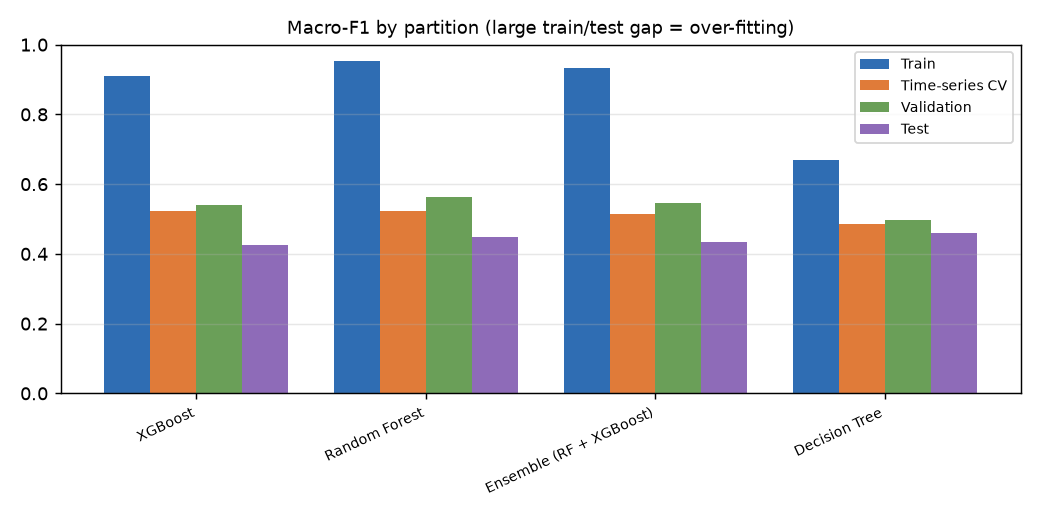

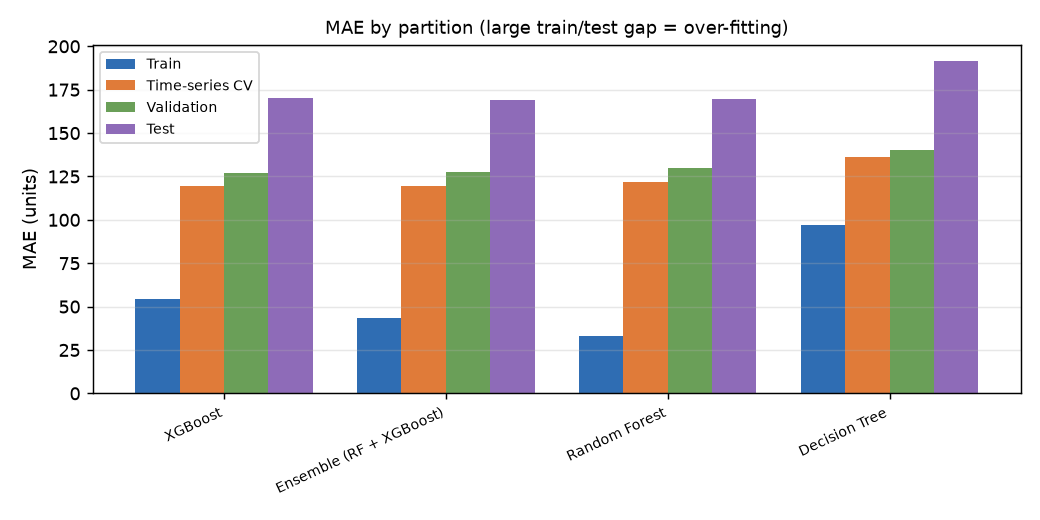

In [3]:
display(Image(filename=str(PATHS.figures_dir / 'classification_train_validation_test.png')))
display(Image(filename=str(PATHS.figures_dir / 'regression_train_validation_test.png')))

## 2. Classification on the held-out test weeks

Best model: XGBoost
              precision    recall  f1-score   support

        High       0.26      0.14      0.18        42
      Medium       0.61      0.75      0.67       220
         Low       0.49      0.37      0.42       120

    accuracy                           0.56       382
   macro avg       0.46      0.42      0.43       382
weighted avg       0.54      0.56      0.54       382



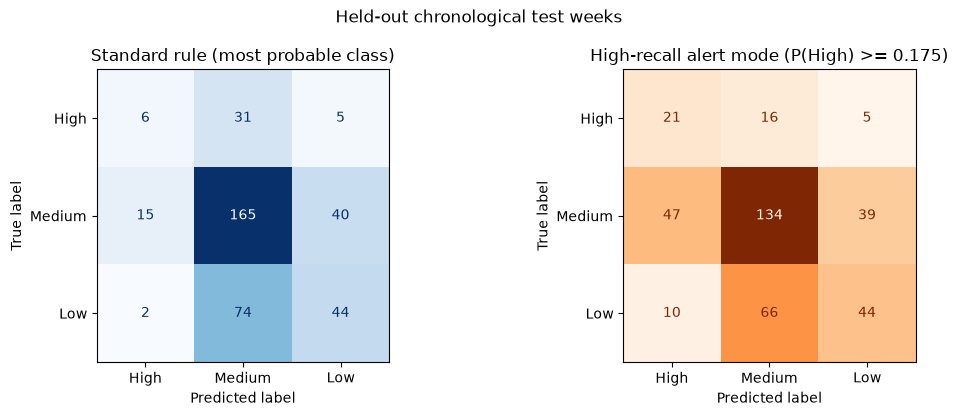

In [4]:
# CMD: Classification report and confusion matrix of the selected model (recomputed from saved test predictions).
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from src.config import RISK_LABELS
from src.config import safe_name
best = classification.loc[classification.selected].iloc[0]
preds = pd.read_csv(PATHS.result('classification_test_predictions.csv'))
y_true, y_std, y_hr = preds.actual_risk, preds[f'pred_{safe_name(best.model)}'], preds.pred_selected_high_recall_mode
print('Best model:', best.model)
print(classification_report(y_true, y_std, labels=list(RISK_LABELS), zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(y_true, y_std, labels=list(RISK_LABELS), cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Standard rule (most probable class)')
ConfusionMatrixDisplay.from_predictions(y_true, y_hr, labels=list(RISK_LABELS), cmap='Oranges', ax=axes[1], colorbar=False)
axes[1].set_title(f'High-recall alert mode (P(High) >= {best.high_recall_threshold:.3f})')
plt.suptitle('Held-out chronological test weeks'); plt.tight_layout(); plt.show()

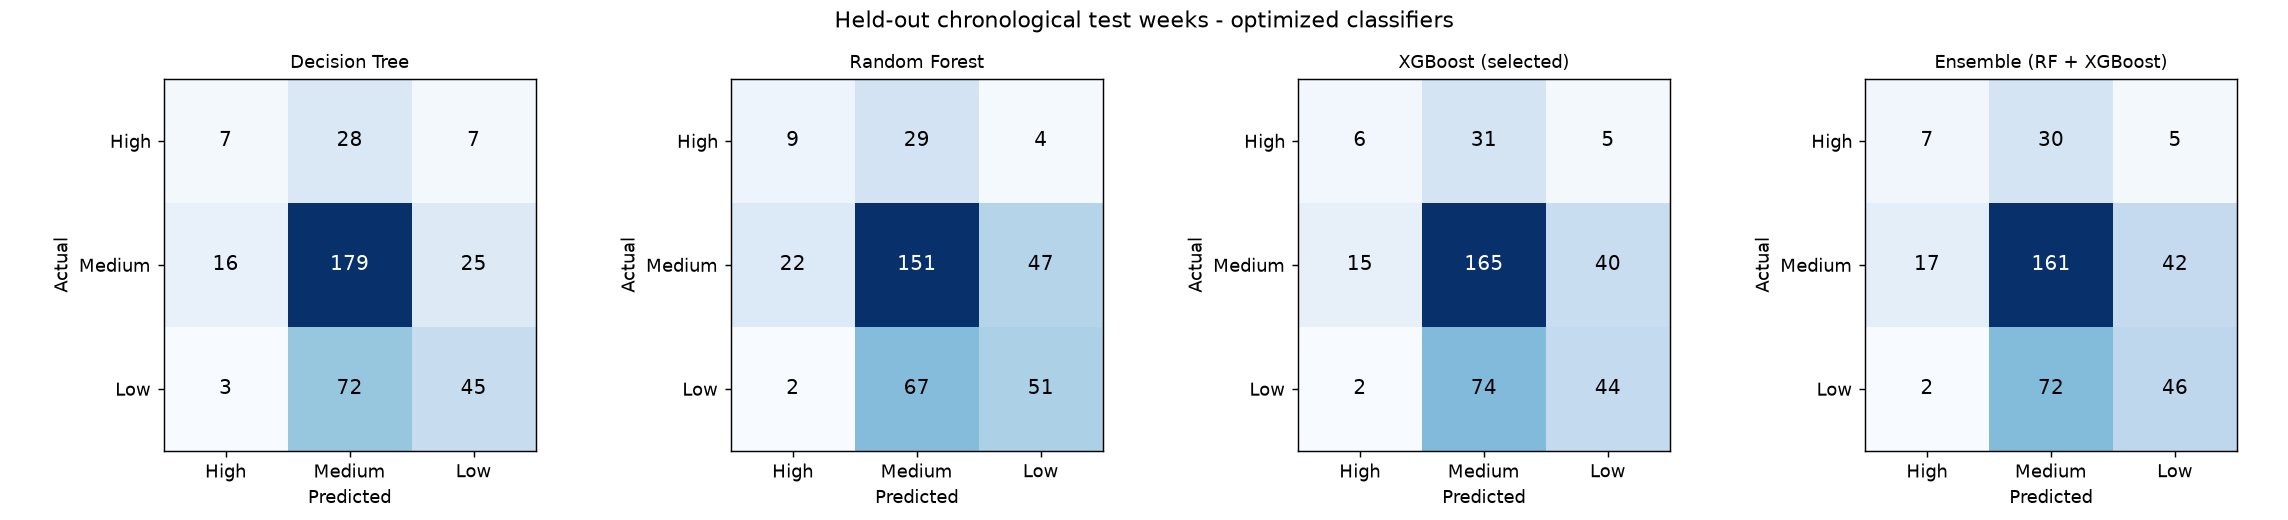

In [5]:
# CMD: Confusion matrices of all three optimized classifiers.
display(Image(filename=str(PATHS.figures_dir / 'confusion_matrices_test.png')))

In [6]:
# CMD: Per-class precision / recall / F1 and per-blood-type High recall.
per_class = pd.read_csv(PATHS.result('classification_per_class_report.csv'))
display(per_class[per_class.model == best.model].round(3))
per_type = pd.read_csv(PATHS.result('classification_per_blood_type.csv'))
display(per_type[per_type.model == best.model][['mode', 'blood_type', 'test_rows', 'actual_high_weeks', 'test_accuracy',
                                                  'test_macro_f1', 'test_high_recall', 'test_high_precision']].round(3))

,model,mode,class,precision,recall,f1-score,support
20,XGBoost,standard,High,0.261,0.143,0.185,42.0
21,XGBoost,standard,Medium,0.611,0.750,0.673,220.0
22,XGBoost,standard,Low,0.494,0.367,0.421,120.0
23,XGBoost,standard,macro avg,0.455,0.420,0.426,382.0
24,XGBoost,standard,weighted avg,0.536,0.563,0.540,382.0
25,XGBoost,high_recall_mode,High,0.269,0.500,0.350,42.0
26,XGBoost,high_recall_mode,Medium,0.620,0.609,0.615,220.0
27,XGBoost,high_recall_mode,Low,0.500,0.367,0.423,120.0
28,XGBoost,high_recall_mode,macro avg,0.463,0.492,0.463,382.0
29,XGBoost,high_recall_mode,weighted avg,0.544,0.521,0.525,382.0


,mode,blood_type,test_rows,actual_high_weeks,test_accuracy,test_macro_f1,test_high_recall,test_high_precision
16,standard,A,95,14,0.611,0.372,0.214,0.429
17,standard,B,96,6,0.500,0.334,0.000,0.000
18,standard,O,96,14,0.656,0.302,0.071,0.200
19,standard,AB,95,8,0.484,0.418,0.250,0.333
20,high_recall_mode,A,95,14,0.558,0.404,0.643,0.333
21,high_recall_mode,B,96,6,0.458,0.354,0.167,0.067
22,high_recall_mode,O,96,14,0.583,0.369,0.571,0.286
23,high_recall_mode,AB,95,8,0.484,0.442,0.375,0.375


### High-risk recall analysis
The standard rule predicts the most probable class. Because missing a shortage is costlier than a false alarm, the **high-recall alert mode** flags HIGH whenever P(High) reaches a threshold chosen on *cross-validation* predictions (development period only) to reach 75% HIGH recall there. The test period shows how well that choice generalizes.

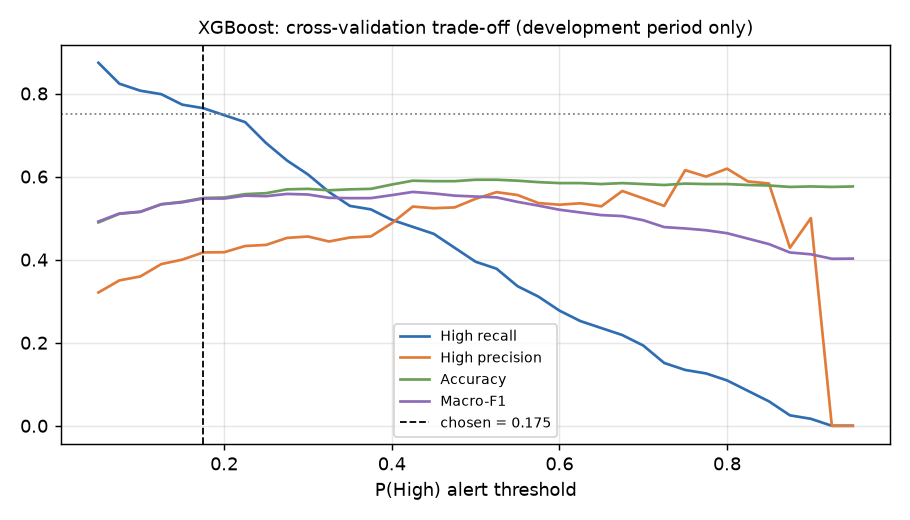

Test-period 95% bootstrap intervals (resampling whole target weeks):


,model,metric,lower_95,median,upper_95
0,XGBoost,accuracy,0.504,0.563,0.618
1,XGBoost,macro_f1,0.368,0.424,0.484
2,XGBoost,high_recall,0.033,0.139,0.281


In [7]:
display(Image(filename=str(PATHS.figures_dir / 'high_risk_threshold_curve.png')))
ci = pd.read_csv(PATHS.result('classification_test_confidence_intervals.csv'))
print('Test-period 95% bootstrap intervals (resampling whole target weeks):'); display(ci.round(3))

## 3. Regression: actual vs predicted demand

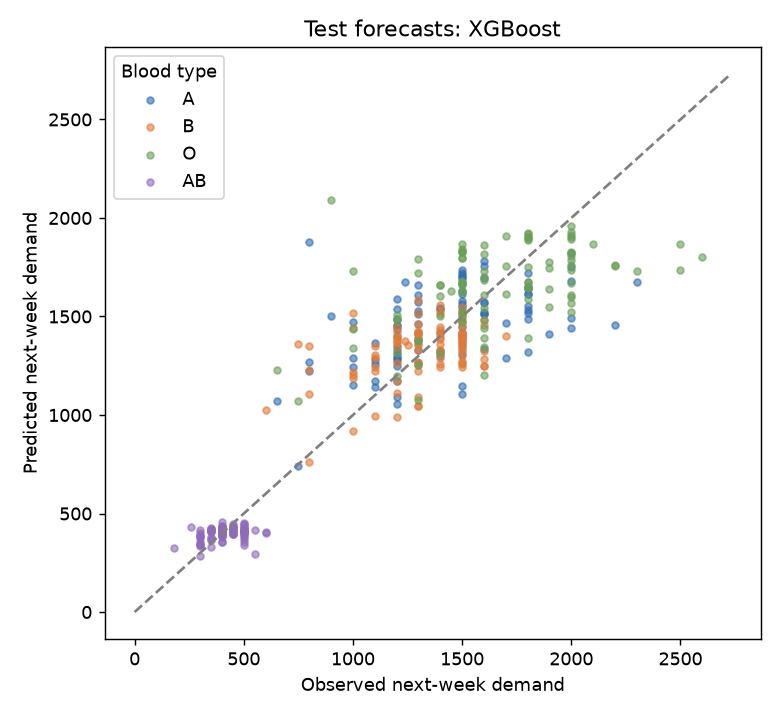

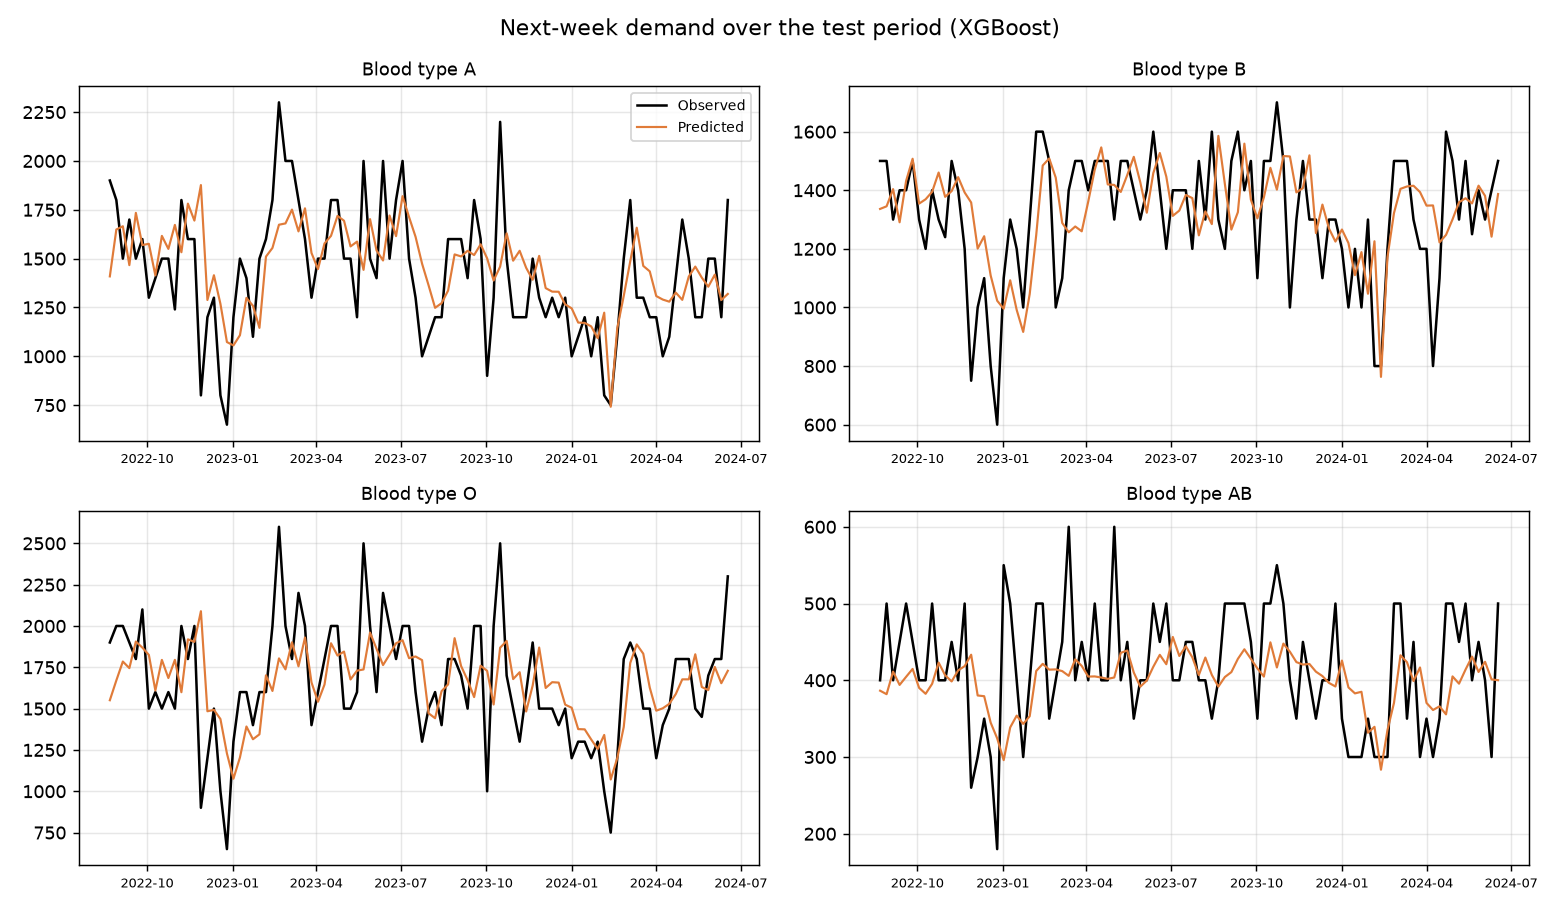

In [8]:
# CMD: Observed vs predicted next-week demand on the test period.
display(Image(filename=str(PATHS.figures_dir / 'regression_actual_vs_predicted.png')))
display(Image(filename=str(PATHS.figures_dir / 'regression_actual_vs_predicted_timeseries.png')))

In [9]:
# CMD: Report error for each blood type, not only combined error.
reg_type = pd.read_csv(PATHS.result('regression_per_blood_type.csv'))
display(reg_type.pivot(index='blood_type', columns='model', values='test_mae').round(2))
display(pd.read_csv(PATHS.result('regression_test_confidence_intervals.csv')).round(2))

model,Decision Tree,Ensemble (RF + XGBoost),Random Forest,XGBoost
blood_type,,,,
A,250.72,220.61,220.78,221.86
AB,63.63,59.55,60.00,59.77
B,170.13,158.61,159.81,158.77
O,281.11,237.30,237.00,241.02


,model,metric,lower_95,median,upper_95
0,XGBoost,mae,151.40,169.59,191.08
1,XGBoost,rmse,202.72,233.29,272.74
2,XGBoost,mape_percent,13.02,15.24,18.08


## 4. Before vs after optimization
*Naive persistence* = "next week equals this week". *Original settings* = the hyper-parameters, features and weighting of the original project, evaluated with exactly the same protocol. `results/original_baseline_run/` also keeps the metrics produced by the original code before refactoring.

,model,stage,cv_macro_f1,validation_macro_f1,test_accuracy,test_macro_f1,test_high_recall
0,Naive persistence,naive baseline,0.486,0.497,0.542,0.475,0.333
1,Decision Tree (original settings),before optimization,0.470,0.449,0.487,0.401,0.286
2,Decision Tree (optimized),after optimization,0.486,0.498,0.605,0.460,0.167
3,Random Forest (original settings),before optimization,0.511,0.532,0.594,0.516,0.357
4,Random Forest (optimized),after optimization,0.522,0.562,0.552,0.449,0.214
5,XGBoost (original settings),before optimization,0.507,0.573,0.552,0.453,0.214
6,XGBoost (optimized),after optimization,0.522,0.540,0.563,0.426,0.143
7,Ensemble (RF + XGBoost) (optimized),after optimization,0.514,0.545,0.560,0.435,0.167


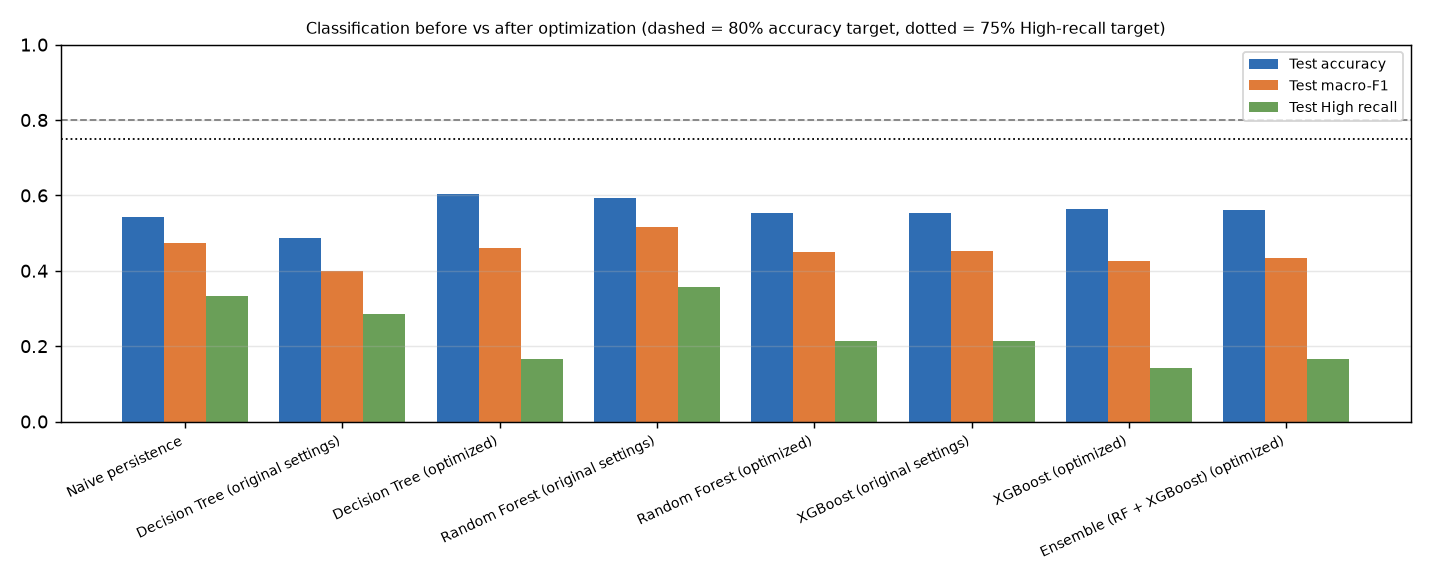

,model,stage,cv_mae,validation_mae,test_mae,test_rmse,test_mape_percent
0,Naive persistence,naive baseline,139.90,134.97,195.21,273.29,17.40
1,Decision Tree (original settings),before optimization,143.52,171.27,201.17,277.70,17.60
2,Decision Tree (optimized),after optimization,136.11,140.24,191.39,262.16,16.76
3,Random Forest (original settings),before optimization,123.30,127.68,169.88,237.90,15.36
4,Random Forest (optimized),after optimization,121.99,129.91,169.40,238.41,15.26
5,XGBoost (original settings),before optimization,121.00,126.13,167.37,232.08,15.32
6,XGBoost (optimized),after optimization,119.37,126.95,170.35,235.39,15.34
7,Ensemble (RF + XGBoost) (optimized),after optimization,119.76,127.40,169.02,235.59,15.23


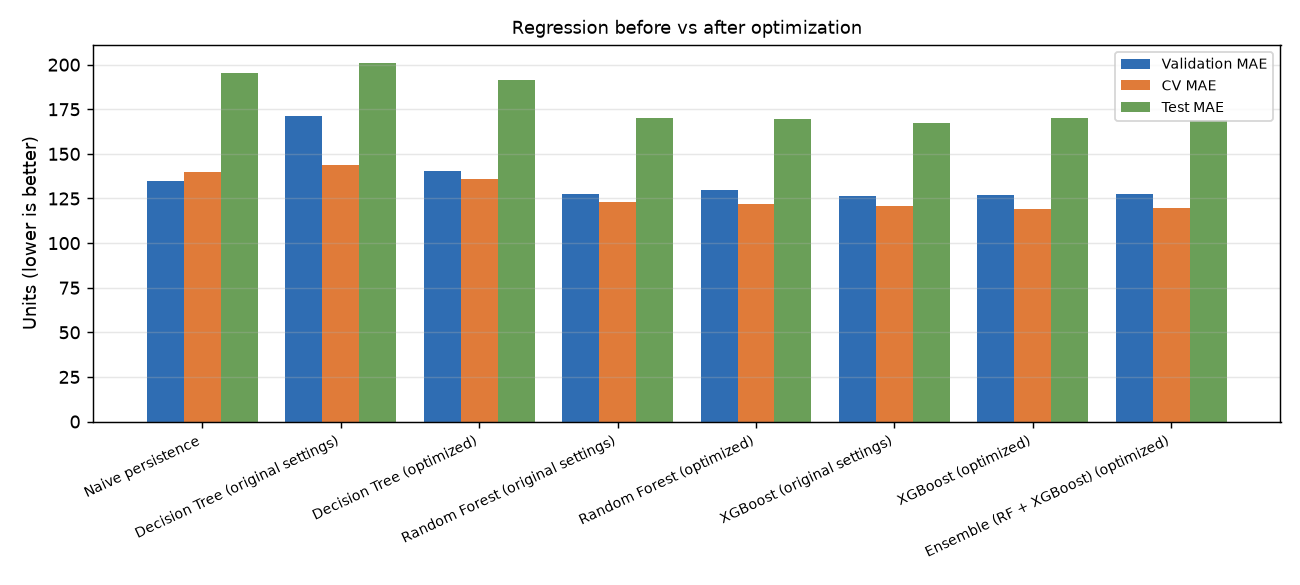

In [10]:
before_c = pd.read_csv(PATHS.result('classification_before_after.csv'))
display(before_c[['model', 'stage', 'cv_macro_f1', 'validation_macro_f1', 'test_accuracy', 'test_macro_f1', 'test_high_recall']].round(3))
display(Image(filename=str(PATHS.figures_dir / 'classification_before_after.png')))
before_r = pd.read_csv(PATHS.result('regression_before_after.csv'))
display(before_r[['model', 'stage', 'cv_mae', 'validation_mae', 'test_mae', 'test_rmse', 'test_mape_percent']].round(2))
display(Image(filename=str(PATHS.figures_dir / 'regression_before_after.png')))
orig = PATHS.results_dir / 'original_baseline_run' / 'classification_metrics.csv'
if orig.exists():
    print('Metrics saved by the ORIGINAL code before refactoring:')
    display(pd.read_csv(orig)[['model', 'selected', 'validation_macro_f1', 'test_accuracy', 'test_macro_f1', 'test_high_recall']].round(3))

## 4b. Version 2 changes: walk-forward retraining and version 1 vs version 2
*Static* = one model fitted on train + validation, then frozen for the whole 20-month test period (version-1 protocol). *Walk-forward* = retrained every few weeks on all outcomes known at that time. The walk-forward **validation** scores (`validation_wf_*`) show the effect of retraining without using the test period.

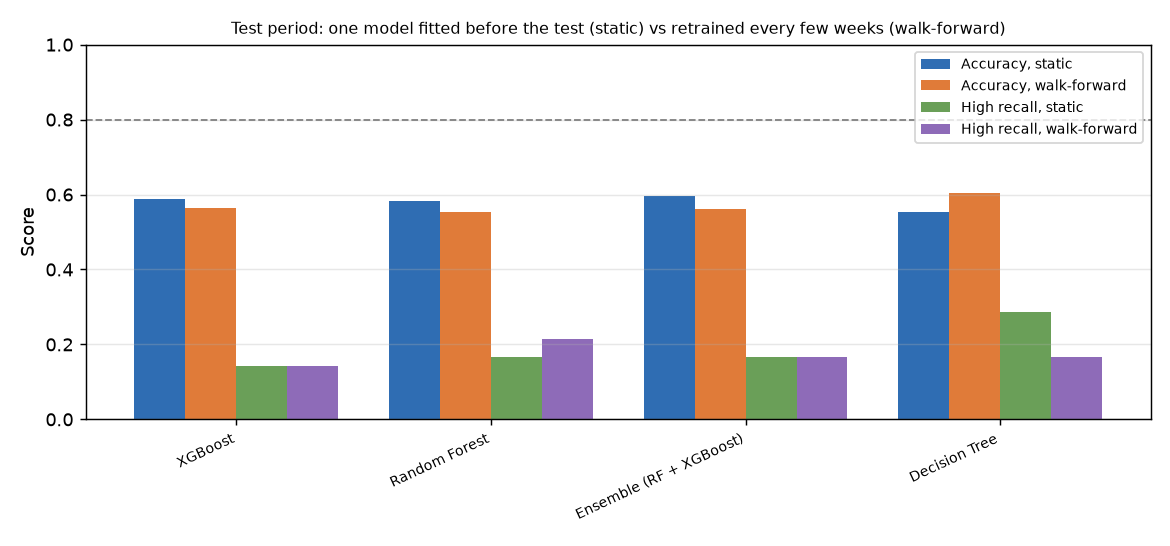

,model,validation_macro_f1,validation_wf_macro_f1,validation_accuracy,validation_wf_accuracy,test_static_accuracy,test_walk_forward_accuracy,test_static_high_recall,test_walk_forward_high_recall
0,XGBoost,0.540,0.548,0.585,0.587,0.589,0.563,0.143,0.143
1,Random Forest,0.562,0.547,0.580,0.569,0.584,0.552,0.167,0.214
2,Ensemble (RF + XGBoost),0.545,0.537,0.574,0.567,0.597,0.560,0.167,0.167
3,Decision Tree,0.498,0.527,0.517,0.561,0.552,0.605,0.286,0.167


In [11]:
display(Image(filename=str(PATHS.figures_dir / 'classification_static_vs_walk_forward.png')))
display(classification[['model', 'validation_macro_f1', 'validation_wf_macro_f1', 'validation_accuracy', 'validation_wf_accuracy',
                        'test_static_accuracy', 'test_walk_forward_accuracy', 'test_static_high_recall', 'test_walk_forward_high_recall']].round(3))
v1 = PATHS.results_dir / 'previous_version_v1'
if v1.exists():
    v1c, v1r = pd.read_csv(v1 / 'classification_metrics.csv'), pd.read_csv(v1 / 'regression_metrics.csv')
    a, b = v1c.loc[v1c.selected].iloc[0], classification.loc[classification.selected].iloc[0]
    ar, br = v1r.loc[v1r.selected].iloc[0], regression.loc[regression.selected].iloc[0]
    display(pd.DataFrame({
        'version 1': [a.model, a.test_accuracy, a.test_macro_f1, a.test_high_recall, a.get('test_high_recall_mode_high_recall'), ar.model, ar.test_mae],
        'version 2': [b.model, b.test_accuracy, b.test_macro_f1, b.test_high_recall, b.test_high_recall_mode_high_recall, br.model, br.test_mae]},
        index=['classifier', 'test accuracy', 'test macro-F1', 'test High recall', 'High recall (alert mode)', 'regressor', 'test MAE']))

## 4c. Original vs corrected dataset (separate experiment)
`python run_pipeline.py --corrected` trains the same pipeline on the corrected copy (date typos fixed, clear entry errors set missing; see `results/data_repair_log.csv`). The two test periods are not identical: the corrected file has 13 more weeks, so its last 15% starts earlier and some labels differ. Compare the tendency, not single points.

In [12]:
corrected = ProjectPaths.for_run('corrected')
if corrected.class_metrics.exists() and corrected.reg_metrics.exists():
    rows = []
    for name, p in (('original', PATHS), ('corrected', corrected)):
        c = pd.read_csv(p.class_metrics); c = c.loc[c.selected].iloc[0]
        r = pd.read_csv(p.reg_metrics); r = r.loc[r.selected].iloc[0]
        t = pd.read_csv(p.result('classification_test_predictions.csv'))
        rows.append({'dataset': name, 'test rows': len(t), 'test High weeks': int((t.actual_risk == 'High').sum()),
                     'classifier': c.model, 'test accuracy': c.test_accuracy, 'test macro-F1': c.test_macro_f1,
                     'test High recall': c.test_high_recall, 'High recall (alert mode)': c.test_high_recall_mode_high_recall,
                     'regressor': r.model, 'test MAE': r.test_mae})
    display(pd.DataFrame(rows).set_index('dataset').round(3))
else:
    print('Run `python run_pipeline.py --corrected` to create the corrected experiment.')

,test rows,test High weeks,classifier,test accuracy,test macro-F1,test High recall,High recall (alert mode),regressor,test MAE
dataset,,,,,,,,,
original,382,42,XGBoost,0.563,0.426,0.143,0.5,XGBoost,170.351
corrected,382,42,XGBoost,0.589,0.457,0.167,0.5,XGBoost,168.434


## 5. Next-week forecast from the last observed week

In [13]:
# CMD / purpose: show transparent next-week predictions from last observed week.
from src.prediction import predict_next_week
forecast = predict_next_week()
display(forecast[['blood_type', 'last_observed_week', 'forecast_week', 'observed_risk', 'predicted_risk', 'p_high',
                  'risk_confidence', 'predicted_risk_high_recall_mode', 'predicted_demand', 'risk_alert']].round(3))

C:\Users\SunLEAP\AppData\Local\Temp\ipykernel_19320\454002771.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  'risk_confidence', 'predicted_risk_high_recall_mode', 'predicted_demand', 'risk_alert']].round(3))


,blood_type,last_observed_week,forecast_week,observed_risk,predicted_risk,p_high,risk_confidence,predicted_risk_high_recall_mode,predicted_demand,risk_alert
0,A,2024-06-17,2024-06-24,Medium,Medium,0.006,0.556,Medium,1570.194946,NOTICE
1,B,2024-06-17,2024-06-24,Medium,Low,0.016,0.666,Low,1504.040039,NONE
2,O,2024-06-17,2024-06-24,Medium,Medium,0.037,0.720,Medium,1933.293945,NOTICE
3,AB,2024-06-17,2024-06-24,Medium,Low,0.004,0.793,Low,420.282013,NONE


## 6. Using the existing models on an external CSV (no retraining)
`predict_external` validates a compatible file, builds the same features in memory and applies the saved models. Nothing in `data/` or `models/` is written. Here the last 120 rows of the Zhejiang file stand in for a "new" file (these weeks overlap the training data, so the scores are optimistic).

In [14]:
import tempfile, os
from src.prediction import predict_external
sample = pd.read_csv(PATHS.raw_data, dtype='string').tail(120)
with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / 'sample_external.csv'
    sample.to_csv(path, index=False)
    out = predict_external(path, save=False)
print(out['report'].summary())
display(out['forecast'][['blood_type', 'forecast_week', 'predicted_risk', 'p_high', 'predicted_demand']].round(3))
display(out['evaluation']['classification'].round(3).head(5))

Rows: 120 | unique dates: 120 | range: 2022-03-07 to 2024-06-17


C:\Users\SunLEAP\AppData\Local\Temp\ipykernel_19320\2840045579.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(out['forecast'][['blood_type', 'forecast_week', 'predicted_risk', 'p_high', 'predicted_demand']].round(3))


,blood_type,forecast_week,predicted_risk,p_high,predicted_demand
0,A,2024-06-24,Medium,0.006,1570.194946
1,B,2024-06-24,Low,0.016,1504.040039
2,O,2024-06-24,Medium,0.037,1933.293945
3,AB,2024-06-24,Low,0.004,420.282013


,mode,rows,external_accuracy,external_macro_precision,external_macro_recall,external_macro_f1,external_high_recall,external_medium_recall,external_low_recall,external_high_precision,external_medium_precision,external_low_precision,blood_type
0,standard,474,0.861,0.880,0.832,0.853,0.804,0.919,0.774,0.938,0.853,0.850,NaN
1,standard,118,0.898,0.940,0.809,0.851,0.889,0.988,0.550,0.941,0.878,1.000,A
2,standard,119,0.857,0.900,0.828,0.859,0.778,0.908,0.800,1.000,0.843,0.857,B
3,standard,119,0.891,0.922,0.825,0.860,0.850,0.974,0.652,0.895,0.871,1.000,O
4,standard,118,0.797,0.859,0.727,0.770,0.556,0.745,0.879,1.000,0.792,0.785,AB


In [16]:
# CMD: Display the best model and its test scores, compared with the proposal targets.
print('Best Model:', best.model)
print(f"Test Accuracy:    {best.test_accuracy:.2%}")
print(f"Test Macro F1:    {best.test_macro_f1:.2%}")
print(f"High-Risk Recall: {best.test_high_recall:.2%}")
print(f"High-Risk Recall, high-recall alert mode: {best.test_high_recall_mode_high_recall:.2%} "
      f"(accuracy {best.test_high_recall_mode_accuracy:.2%})")
best_r = regression.loc[regression.selected].iloc[0]
print(f"Best regressor: {best_r.model} | test MAE {best_r.test_mae:.1f} units | MAPE {best_r.test_mape_percent:.2f}%")

Best Model: XGBoost
Test Accuracy:    56.28%
Test Macro F1:    42.64%
High-Risk Recall: 14.29%
High-Risk Recall, high-recall alert mode: 50.00% (accuracy 52.09%)
Best regressor: XGBoost | test MAE 170.4 units | MAPE 15.34%


### Final report discussion
Discuss class imbalance (weighting strategies tested), duplicate-date reconciliation, **temporal drift** (High-risk share varies from ~1% to ~26% by year), the retrospective chronological split, observed vs predicted risk, the accuracy/recall trade-off of the high-recall alert mode, the width of the test confidence intervals (only ~36 High weeks in the test period), and why results on Zhejiang data do **not** validate deployment for Cambodian blood services. Retraining on data with verified weekly timestamp definitions is recommended before any operational use.